# Multilayer perceptron for XOR

A reproducible 2–3–1 sigmoid network evaluated on the four binary XOR combinations.

## Architecture and implementation

The targets are [0, 1, 1, 0]. Two inputs feed three hidden sigmoid units and one sigmoid output. No bias parameters are included, matching the reference architecture. A class threshold of 0.5 converts outputs to binary predictions. Sigmoid scores are not treated as calibrated probabilities.

The reference code's inconsistent `weights1` name is corrected to the output-weight matrix. Hidden deltas use its transpose, giving `(4, 1) @ (1, 3) → (4, 3)`; the incompatible multiplication shown in the walkthrough is excluded from the executable analysis. Hidden deltas are computed before either weight matrix is updated. Seed 1 fixes the baseline initialisation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
print('NumPy:', np.__version__)


NumPy: 2.4.4


In [2]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

z=np.array([-20.5,-5,0,5,40])
display(pd.DataFrame({'Input':z,'Sigmoid':sigmoid(z),'Derivative':sigmoid(z)*(1-sigmoid(z))}))
X=np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
y=np.array([[0],[1],[1],[0]],dtype=float)

def forward(X,w0,w1):
    hidden=sigmoid(X @ w0)
    return hidden,sigmoid(hidden @ w1)

def fit_xor(epochs=400000,learning_rate=0.6,seed=1):
    rng=np.random.RandomState(seed)
    w0=2*rng.random_sample((2,3))-1
    w1=2*rng.random_sample((3,1))-1
    history=[]
    for epoch in range(epochs):
        hidden,pred=forward(X,w0,w1)
        residual=y-pred
        if epoch % 1000==0:
            history.append((epoch,float(np.mean(abs(residual))),float(0.5*np.sum(residual**2))))
        delta_output=residual*pred*(1-pred)
        delta_hidden=(delta_output @ w1.T)*hidden*(1-hidden)
        w1+=learning_rate*(hidden.T @ delta_output)
        w0+=learning_rate*(X.T @ delta_hidden)
    hidden,pred=forward(X,w0,w1)
    history.append((epochs,float(np.mean(abs(y-pred))),float(0.5*np.sum((y-pred)**2))))
    return pred,w0,w1,pd.DataFrame(history,columns=['Epoch','MAE','Half summed squared error'])

pred,w0,w1,history=fit_xor()
classes=(pred>=0.5).astype(int)
display(pd.DataFrame({'x₁':X[:,0].astype(int),'x₂':X[:,1].astype(int),'Target':y.ravel().astype(int),'Sigmoid output':pred.ravel(),'Prediction':classes.ravel()}))
print('Final MAE:',float(np.mean(abs(y-pred))))
print('Truth-table accuracy:',float(np.mean(classes==y)))
print('Final weight matrices:');print(w0);print(w1)


Input,Sigmoid,Derivative
-20.5,1.250153e-09,1.250153e-09
-5.0,6.692851e-03,6.648057e-03
0.0,5.000000e-01,2.500000e-01
5.0,9.933071e-01,6.648057e-03
40.0,1.000000e+00,0.000000e+00


x₁,x₂,Target,Sigmoid output,Prediction
0,0,0,0.008195,0
0,1,1,0.993546,1
1,0,1,0.993547,1
1,1,0,0.008977,0


Final MAE: 0.007519672210560107
Truth-table accuracy: 1.0
Final weight matrices:
[[-12.75232112   5.81765542  -1.02823794]
 [  5.81413455 -12.76080175  -1.02839215]]
[[ 16.08443006]
 [ 16.08555118]
 [-41.76207247]]


## Optimisation and evaluation

The update follows the negative gradient of half the summed squared error, with a sigmoid derivative at each layer. MAE is recorded as a reporting metric; it is not the objective differentiated by the update. Final outputs are recomputed after the last update. `1 − MAE` is not classification accuracy. The learning curve uses actual epoch numbers rather than positions in a list of sampled errors.

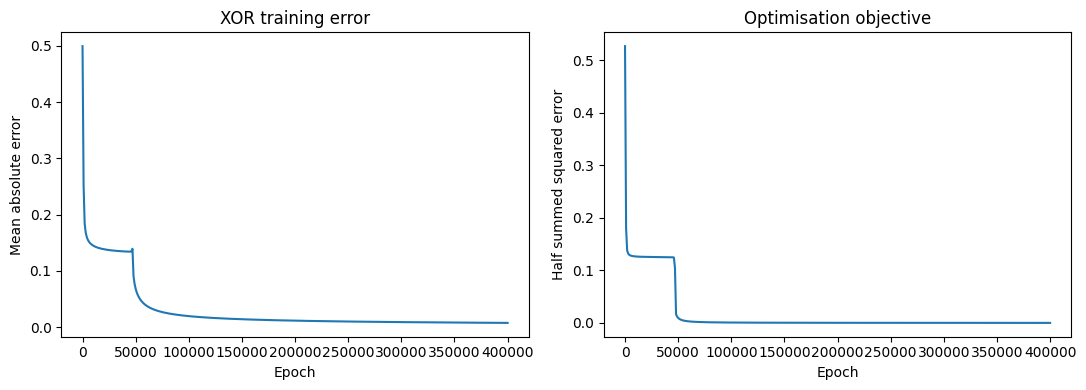

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(history.Epoch,history.MAE)
axes[0].set(xlabel='Epoch',ylabel='Mean absolute error',title='XOR training error')
axes[1].plot(history.Epoch,history['Half summed squared error'])
axes[1].set(xlabel='Epoch',ylabel='Half summed squared error',title='Optimisation objective')
plt.tight_layout();plt.show()


## Controlled comparisons

Learning rates are compared for 20,000 epochs from seed 1. A second seed tests initialisation sensitivity at the same budget and baseline rate. These comparisons are distinct from the 400,000-epoch baseline. They are descriptive checks on the complete truth table, not independent test-set evaluations.

In [4]:
comparison=[]
for rate,seed in [(0.1,1),(0.6,1),(2.0,1),(0.6,7)]:
    p,_,_,_=fit_xor(epochs=20000,learning_rate=rate,seed=seed)
    comparison.append({'Learning rate':rate,'Seed':seed,'Epochs':20000,'MAE':float(np.mean(abs(y-p))),'Accuracy':float(np.mean((p>=0.5)==y))})
display(pd.DataFrame(comparison))
summary={'outputs':pred.ravel().tolist(),'mae':float(np.mean(abs(y-pred))),'accuracy':float(np.mean(classes==y)),'comparisons':comparison}


Learning rate,Seed,Epochs,MAE,Accuracy
0.1,1,20000,0.164687,0.75
0.6,1,20000,0.138456,0.75
2.0,1,20000,0.031816,1.00
0.6,7,20000,0.040840,1.00


## Interpretation and limitations

XOR cannot be separated by one linear decision boundary. Hidden nonlinear units provide a representation that can support its classification. The absence of trainable biases restricts this implementation; results should not be presented as evidence that all networks with three hidden units will converge from arbitrary initial weights. Sigmoid saturation produces small derivatives and can slow updates. The four records exhaust the Boolean input domain, so perfect truth-table agreement is a functional check rather than evidence of performance on noisy or unseen real-world observations.

## Provenance and reproducibility

Adapted from the reference notebooks credited to Dr Mike Lakoju. The implementations retain the reference inputs and model structure; corrections and extensions are identified above. All data are defined in code. Cells were executed sequentially in an independent Python namespace, with outputs embedded. Analysis and editorial preparation used AI assistance.
